<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/15_pipeline_diagram_sahil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline diagram: from the raw files to both questions

Draws `figures/15_pipeline_diagram.png`. Each box is one step, with the number of the notebook it comes from in its top-left corner. Amber boxes are choices the team made; dashed boxes are checks or side analyses. The diagram reads no data: every number on it is typed into the labels cell below and comes from the notebook named here.

| Box | Numbers on the diagram | Notebook |
| --- | --- | --- |
| Raw data | 2 CSV files; 21,631 games with details (the ratings file has 21,831 rows) | 01 |
| PCA | 7 attributes; 17,636 games; 70.5% of the variance in 3 components | 03 |
| Imputed rows | 20,928 games | 12 |
| Missing values | 21,379 games kept | 05 |
| Split | 14,964 training games, 6,415 test games | 05 |
| Choose | tie margin 0.005; tree test RMSE 0.702; dummy 0.927 | 13 |
| Decision rule | cut-off 7.5; a flop costs 3 times a missed hit; test cost 1,570, against 1,730 for making no game | 07 |
| Rating cut-offs | 30 to 500 ratings | 14 |
| Train on the past | trained on games up to 2016, tested on 2017 to 2021 | 08 |

In [1]:
# --- Sahil Dalal: task 8, pipeline diagram ---
# [AI-assisted] Claude Code (Claude Opus 5.5), 2026-11-11. Every code and markdown cell in this notebook was generated with Claude Code and reviewed, run and edited by Sahil Dalal.
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Figures go to the repository's figures folder when run from notebooks/, as in the other notebooks.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

## 1. Every label on the diagram, in one place

In [2]:
# [AI-assisted] Claude Code (Claude Opus 5.5), 2026-11-11. Box styles and every label on the diagram; reviewed and edited by Sahil Dalal.
# Box styles: a plain step, a choice the team made, a check or side analysis, and a choice that is also a check.
STYLES = {
    "step":         dict(face="#E8EEF4", edge="#4A6A8A", ls="-"),
    "choice":       dict(face="#FDF0D5", edge="#B7791F", ls="-"),
    "check":        dict(face="#FFFFFF", edge="#7A7A7A", ls="--"),
    "choice_check": dict(face="#FDF0D5", edge="#B7791F", ls="--"),
}

# Every word on the diagram: (key, x, y, width, height, style, notebook, title, detail), on a 100 x 56.25 grid.
TOP, BOT, H = 35.5, 8.5, 12.0
BOXES = [
    ("raw",   0.3, 22.5, 11.4, 11.0, "step", "", "Raw data", "2 TidyTuesday\nCSV files;\n21,631 games\nwith details"),
    ("clean", 12.9, 21.5, 13.3, 13.0, "step", "01", "Cleaning", "zeros and unknown\nlists set to missing;\nafter-release\ncolumns not used\nas inputs"),
    ("d1", 29.0, TOP, 16.1, H, "step", "02", "Charts by decade", "1970s to 2020s,\none chart per attribute"),
    ("d2", 47.1, TOP, 16.1, H, "step", "03", "PCA", "7 attributes,\n17,636 games;\n3 components\nhold 70.5%"),
    ("d3", 65.2, TOP, 16.1, H, "step", "09", "Third variable", "wargames vs the rest"),
    ("d4", 83.3, TOP, 16.1, H, "step", "10", "Format vs mechanics", "both kinds of shift\non one scale"),
    ("d2c", 47.1, 49.0, 16.1, 6.8, "check", "12", "Imputed rows", "k-NN fill, 20,928 games"),
    ("p1", 29.0, BOT, 12.8, H, "choice", "05", "Missing values", "21,379 games kept;\nmedian fill inside\nthe Pipeline"),
    ("p2", 43.4, BOT, 12.8, H, "step", "05", "Split", "70/30 at random:\n14,964 train,\n6,415 test"),
    ("p3", 57.8, BOT, 12.8, H, "step", "05, 06", "Models", "tree, k-NN,\nnetwork, linear;\ntuned by 5-fold CV"),
    ("p4", 72.2, BOT, 12.8, H, "choice", "13", "Choose", "within 0.005, the\nsimplest wins: tree;\ntest RMSE 0.702\n(dummy 0.927)"),
    ("p5", 86.6, BOT - 2.0, 12.8, H + 4.0, "choice", "07", "Decision rule", "make it if predicted\nat or above 7.5;\na flop costs 3x\na missed hit;\ntest cost 1,570\n(make none: 1,730)"),
    ("p1c", 29.0, 0.4, 12.8, 6.6, "check", "14", "Rating cut-offs", "30 to 500 ratings"),
    ("p2c", 43.4, 0.4, 12.8, 6.6, "choice_check", "08", "Train on the past", "up to 2016,\ntest 2017 to 2021"),
]
LANES = [(29.0, 48.9, "Descriptive question"), (29.0, 21.6, "Predictive question")]
ARROWS = [("raw", "clean"), ("d1", "d2"), ("d2", "d3"), ("d3", "d4"), ("p1", "p2"), ("p2", "p3"), ("p3", "p4"), ("p4", "p5")]
LINKS = [("d2", "d2c"), ("p1", "p1c"), ("p2", "p2c")]
LEGEND = [("choice", "a choice we made"), ("check", "a check or side analysis")]
INK, BLUE, GREY = "#1F2933", "#4A6A8A", "#7A7A7A"

## 2. Draw and save

saved ../figures/15_pipeline_diagram.png


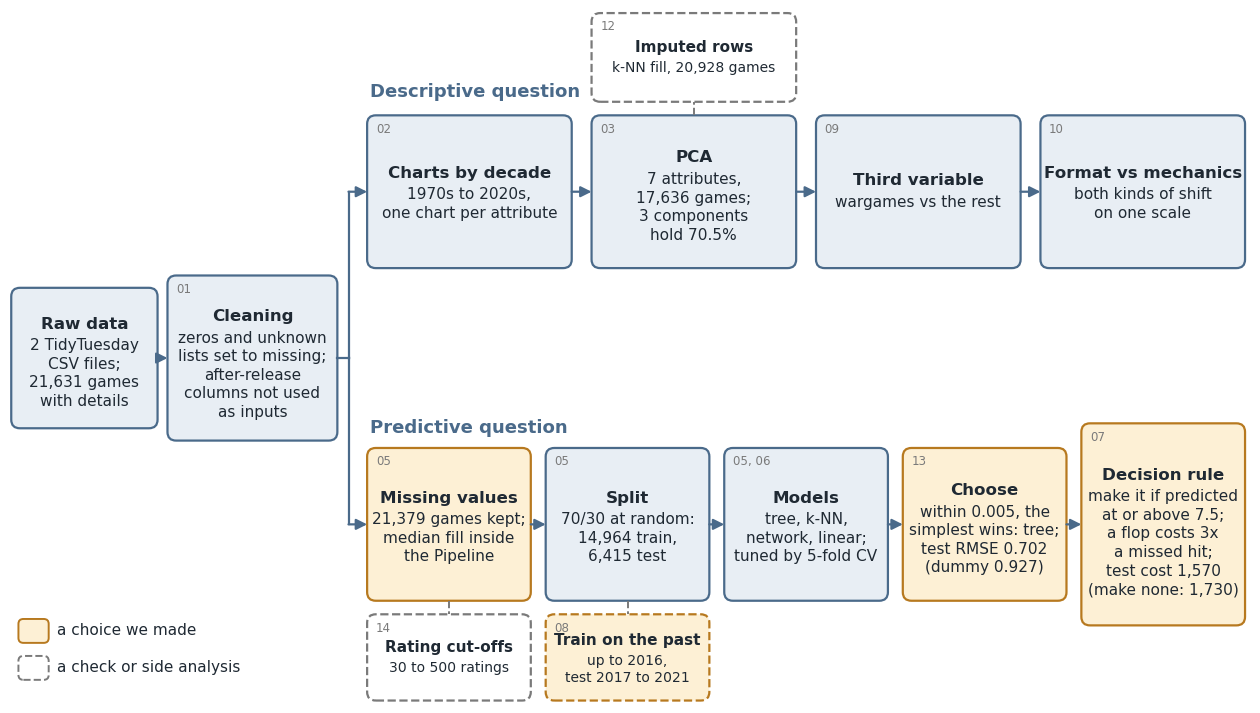

In [3]:
# [AI-assisted] Claude Code (Claude Opus 5.5), 2026-11-11. Draw the boxes, arrows, lanes and legend, then save the figure; reviewed and edited by Sahil Dalal.
def draw(out_path):
    fig, ax = plt.subplots(figsize=(16, 9))
    ax.set_xlim(0, 100); ax.set_ylim(0, 56.25); ax.axis("off")
    unit_pt = 9 * 72 / 56.25          # points per vertical data unit
    geo = {}
    for key, x, y, w, h, style, nb, title, detail in BOXES:
        s = STYLES[style]
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.2,rounding_size=0.7",
                                    facecolor=s["face"], edgecolor=s["edge"], linewidth=1.6, linestyle=s["ls"]))
        small = h < 8
        tsize, dsize = (11, 10) if small else (12, 11)
        lines = detail.count("\n") + 1
        title_h = tsize * 1.2 / unit_pt
        detail_h = lines * dsize * 1.3 / unit_pt
        gap = 0.5
        top = y + h / 2 + (title_h + gap + detail_h) / 2
        ax.text(x + w / 2, top, title, ha="center", va="top", fontsize=tsize, fontweight="bold", color=INK)
        ax.text(x + w / 2, top - title_h - gap, detail, ha="center", va="top", fontsize=dsize, color=INK, linespacing=1.3)
        if nb:
            ax.text(x + 0.5, y + h - 0.4, nb, ha="left", va="top", fontsize=8.5, color=GREY)
        geo[key] = (x, y, w, h)
    arrow = dict(arrowstyle="-|>", color=BLUE, linewidth=1.6, mutation_scale=16, shrinkA=0, shrinkB=0)
    def right_mid(k): x, y, w, h = geo[k]; return (x + w + 0.2, y + h / 2)
    def left_mid(k): x, y, w, h = geo[k]; return (x - 0.2, y + h / 2)
    for a, b in ARROWS:
        ax.annotate("", xy=left_mid(b), xytext=right_mid(a), arrowprops=arrow)
    # Cleaning feeds both questions: right, then up or down, then into each lane's first box.
    sx, sy = right_mid("clean"); bend_x = 27.3
    ax.plot([sx, bend_x], [sy, sy], color=BLUE, linewidth=1.6)
    for first in ("d1", "p1"):
        tx, ty = left_mid(first)
        ax.plot([bend_x, bend_x], [sy, ty], color=BLUE, linewidth=1.6)
        ax.annotate("", xy=(tx, ty), xytext=(bend_x, ty), arrowprops=arrow)
    for a, b in LINKS:
        ax_, ay, aw, ah = geo[a]; bx, by, bw, bh = geo[b]
        if by > ay: y0, y1 = ay + ah + 0.2, by - 0.2
        else: y0, y1 = ay - 0.2, by + bh + 0.2
        ax.plot([ax_ + aw / 2] * 2, [y0, y1], color=GREY, linewidth=1.4, linestyle="--")
    for x, y, text in LANES:
        ax.text(x, y, text, ha="left", va="bottom", fontsize=13, fontweight="bold", color=BLUE)
    for i, (style, text) in enumerate(LEGEND):
        s = STYLES[style]; ly = 5.0 - i * 3.0
        ax.add_patch(FancyBboxPatch((0.8, ly), 2.2, 1.7, boxstyle="round,pad=0.12,rounding_size=0.4",
                                    facecolor=s["face"], edgecolor=s["edge"], linewidth=1.4, linestyle=s["ls"]))
        ax.text(3.8, ly + 0.85, text, va="center", fontsize=11, color=INK)
    fig.savefig(out_path, dpi=200, bbox_inches="tight", facecolor="white")
    print("saved", out_path)
    return fig

draw(os.path.join(FIG_DIR, "15_pipeline_diagram.png"))
plt.show()